### Step1: OLS Estimation with same date data

In [1]:
import pandas as pd
import statsmodels.formula.api as smf

datasets = {
    "Qantas": pd.read_csv(r"C:\Users\ALIENWARE\OneDrive\Desktop\26s2\ECMT3150\group project\Qantas_regression_data.csv"),
    "United": pd.read_csv(r"C:\Users\ALIENWARE\OneDrive\Desktop\26s2\ECMT3150\group project\United_regression_data.csv"),
    "Singapore": pd.read_csv(r"C:\Users\ALIENWARE\OneDrive\Desktop\26s2\ECMT3150\group project\Singapore_regression_data.csv")
}

formula = (
    "Airline_Return ~ Oil_Return + D "
    "+ Oil_Interaction + Market_Return"
)

models = {}

qantas_model = smf.ols(formula, data=datasets["Qantas"]).fit()

united_model = smf.ols(formula, data=datasets["United"]).fit()

singapore_model = smf.ols(formula, data=datasets["Singapore"]).fit()

# Qantas Airlines Model Summary
print(qantas_model.summary())


                            OLS Regression Results                            
Dep. Variable:         Airline_Return   R-squared:                       0.237
Model:                            OLS   Adj. R-squared:                  0.236
Method:                 Least Squares   F-statistic:                     189.7
Date:                Wed, 28 Oct 2026   Prob (F-statistic):          8.56e-142
Time:                        22:34:52   Log-Likelihood:                -4914.2
No. Observations:                2451   AIC:                             9838.
Df Residuals:                    2446   BIC:                             9868.
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                      coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------
Intercept           0.0330      0.063     

In [2]:
# United Airlines Model Summary
print(united_model.summary())

                            OLS Regression Results                            
Dep. Variable:         Airline_Return   R-squared:                       0.284
Model:                            OLS   Adj. R-squared:                  0.283
Method:                 Least Squares   F-statistic:                     240.0
Date:                Wed, 28 Oct 2026   Prob (F-statistic):          8.59e-174
Time:                        22:34:52   Log-Likelihood:                -5882.0
No. Observations:                2426   AIC:                         1.177e+04
Df Residuals:                    2421   BIC:                         1.180e+04
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                      coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------
Intercept          -0.0305      0.096     

In [3]:
# Singapore Airlines Model Summary
print(singapore_model.summary())

                            OLS Regression Results                            
Dep. Variable:         Airline_Return   R-squared:                       0.346
Model:                            OLS   Adj. R-squared:                  0.345
Method:                 Least Squares   F-statistic:                     319.8
Date:                Wed, 28 Oct 2026   Prob (F-statistic):          5.22e-221
Time:                        22:34:52   Log-Likelihood:                -3622.9
No. Observations:                2419   AIC:                             7256.
Df Residuals:                    2414   BIC:                             7285.
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                      coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------
Intercept           0.0410      0.038     

### Step2: Hypothesis Testing

### Hypothesis Specification

The main objective of the hypothesis test is to determine whether positive and negative oil-price changes have asymmetric effects on airline stock returns.

The econometric model is specified as:

$$
r_{i,t} = \alpha_i + \beta_{1i}OilReturn_t + \beta_{2i}D_t
+ \beta_{3i}(OilReturn_t \times D_t)
+ \gamma_i MarketReturn_{i,t} + u_{i,t}
$$

The null and alternative hypotheses are:

$$
H_0: \beta_{3i} = 0
$$

$$
H_1: \beta_{3i} \neq 0
$$

Under the null hypothesis, positive and negative oil-price changes have the same marginal effect on airline stock returns. Under the alternative hypothesis, the effects differ significantly, indicating an asymmetric relationship.

A two-sided t-test is conducted at the 5% significance level:

$$
t = \frac{\hat{\beta}_{3i}}{SE(\hat{\beta}_{3i})}
$$

The decision rule is:

- If $p < 0.05$, reject $H_0$, indicating statistically significant asymmetric effects.
- If $p \geq 0.05$, fail to reject $H_0$, indicating insufficient evidence of asymmetric effects.

The hypothesis is tested separately for Qantas Airways, United Airlines, and Singapore Airlines. Initial tests use conventional OLS standard errors, while subsequent analysis employs Newey-West HAC standard errors to account for potential heteroskedasticity and serial correlation.

In [4]:
models = {
    "Qantas": qantas_model,
    "United": united_model,
    "Singapore": singapore_model
}

for name, model in models.items():

    print(f"\n===== {name}: Asymmetry Test =====")

    test = model.t_test("Oil_Interaction = 0")

    print(test)

    p_value = float(model.pvalues["Oil_Interaction"])

    if p_value < 0.05:
        print("Reject H0: Significant asymmetry.")
    else:
        print("Fail to reject H0: No significant asymmetry.")


===== Qantas: Asymmetry Test =====
                             Test for Constraints                             
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
c0            -0.0520      0.030     -1.763      0.078      -0.110       0.006
Fail to reject H0: No significant asymmetry.

===== United: Asymmetry Test =====
                             Test for Constraints                             
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
c0            -0.0767      0.045     -1.714      0.087      -0.164       0.011
Fail to reject H0: No significant asymmetry.

===== Singapore: Asymmetry Test =====
                             Test for Constraints                             
                 coef    std err          t      P>|t|      [0.025      0.975]
---------

### Interpretation of Hypothesis Testing Results

The asymmetry hypothesis is tested separately for Qantas Airways, United Airlines, and Singapore Airlines at the 5% significance level.

**Qantas Airways:** The estimated interaction coefficient is $\hat{\beta}_3=-0.0520$, with a t-statistic of $-1.763$ and a p-value of $0.078$. Since $p>0.05$, we fail to reject $H_0$. This suggests insufficient evidence of asymmetric oil-price effects at the 5% significance level, although the coefficient is significant at the 10% level.

**United Airlines:** The estimated interaction coefficient is $\hat{\beta}_3=-0.0767$, with a t-statistic of $-1.714$ and a p-value of $0.087$. Since $p>0.05$, we fail to reject $H_0$. Therefore, there is insufficient evidence of asymmetric oil-price effects at the 5% significance level.

**Singapore Airlines:** The estimated interaction coefficient is $\hat{\beta}_3=-0.0377$, with a t-statistic of $-2.121$ and a p-value of $0.034$. Since $p<0.05$, we reject $H_0$, indicating statistically significant asymmetric oil-price effects.

**Overall**, all three airlines have negative estimated interaction coefficients, suggesting that the oil-return slope is lower during periods of rising oil prices than during periods of falling oil prices. However, only Singapore Airlines exhibits statistically significant asymmetry at the 5% level under conventional OLS inference.

These findings are preliminary, as the tests use non-robust OLS standard errors. The significance of the estimated effects will be reassessed using Newey-West HAC standard errors.

In [5]:
# Calculate Positive and Negative Oil Effects(Slopes)
for name, model in models.items():

    beta_down = model.params["Oil_Return"]

    beta_up = (
        model.params["Oil_Return"]
        + model.params["Oil_Interaction"]
    )

    print(f"\n{name}")
    print(f"Oil decrease slope: {beta_down:.4f}")
    print(f"Oil increase slope: {beta_up:.4f}")
    print(f"Difference: {model.params['Oil_Interaction']:.4f}")


Qantas
Oil decrease slope: -0.0041
Oil increase slope: -0.0562
Difference: -0.0520

United
Oil decrease slope: -0.0066
Oil increase slope: -0.0832
Difference: -0.0767

Singapore
Oil decrease slope: 0.0219
Oil increase slope: -0.0158
Difference: -0.0377


### Interpretation of Positive and Negative Oil-Price Effects

The estimated marginal effects of oil-price changes are calculated as:

$$
\beta_{\text{down}}=\beta_1
$$

$$
\beta_{\text{up}}=\beta_1+\beta_3
$$

Qantas Airways: The estimated slope for oil-price decreases is -0.0041, while the slope for oil-price increases is -0.0562. This suggests that Qantas stock returns exhibit a more negative relationship with oil returns when oil prices increase.

United Airlines: The estimated slopes are -0.0066 for oil-price decreases and -0.0832 for oil-price increases. United exhibits the largest negative estimated slope during oil-price increases among the three airlines.

Singapore Airlines: The estimated slope is 0.0219 for oil-price decreases and -0.0158 for oil-price increases. This indicates a change in the sign of the estimated relationship, with positive sensitivity during oil-price decreases and negative sensitivity during oil-price increases.

Overall, all three airlines exhibit lower estimated oil-return slopes during periods of rising oil prices. United has the largest estimated slope difference in absolute value (-0.0767), followed by Qantas (-0.0520) and Singapore (-0.0377). However, differences in coefficient magnitudes do not necessarily imply statistically significant differences across airlines.

These estimates describe conditional associations rather than causal effects. Their statistical significance should be evaluated using the hypothesis tests and subsequently reassessed with HAC robust standard errors.

In [6]:
# Test Whether Each Directional Slope Is Significant
for name, model in models.items():

    print(f"\n===== {name} =====")

    print("\nOil Decrease Effect:")
    print(model.t_test("Oil_Return = 0"))

    print("\nOil Increase Effect:")
    print(model.t_test(
        "Oil_Return + Oil_Interaction = 0"
    ))


===== Qantas =====

Oil Decrease Effect:
                             Test for Constraints                             
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
c0            -0.0041      0.019     -0.220      0.826      -0.041       0.033

Oil Increase Effect:
                             Test for Constraints                             
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
c0            -0.0562      0.023     -2.465      0.014      -0.101      -0.011

===== United =====

Oil Decrease Effect:
                             Test for Constraints                             
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
c0            -0.0066    

In [7]:
print("United — Oil Decrease Effect")
print(united_model.t_test("Oil_Return = 0"))

print("United — Oil Increase Effect")
print(united_model.t_test(
    "Oil_Return + Oil_Interaction = 0"
))

United — Oil Decrease Effect
                             Test for Constraints                             
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
c0            -0.0066      0.029     -0.230      0.818      -0.063       0.050
United — Oil Increase Effect
                             Test for Constraints                             
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
c0            -0.0832      0.035     -2.383      0.017      -0.152      -0.015


In [8]:
print("Singapore — Oil Decrease Effect")
print(singapore_model.t_test("Oil_Return = 0"))

print("Singapore — Oil Increase Effect")
print(singapore_model.t_test(
    "Oil_Return + Oil_Interaction = 0"
))

Singapore — Oil Decrease Effect
                             Test for Constraints                             
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
c0             0.0219      0.011      1.943      0.052      -0.000       0.044
Singapore — Oil Increase Effect
                             Test for Constraints                             
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
c0            -0.0158      0.014     -1.146      0.252      -0.043       0.011


###  Interpretation of Individual Directional Effects

To further examine the relationship between oil-price changes and airline stock returns, separate hypothesis tests are conducted for the estimated slopes during oil-price decreases and increases:

$$
H_0:\beta_1=0
$$

$$
H_0:\beta_1+\beta_3=0
$$

**Qantas Airways:** The estimated slope during oil-price decreases is -0.0041 (p = 0.826), indicating no statistically significant relationship. In contrast, the slope during oil-price increases is -0.0562 (p = 0.014), which is significantly negative at the 5% level. This suggests that Qantas stock returns are negatively associated with rising oil prices, while the estimated relationship during oil-price decreases is not statistically significant.

**United Airlines:** The estimated slope during oil-price decreases is -0.0066 (p = 0.818), which is not statistically significant. However, the slope during oil-price increases is -0.0832 (p = 0.017), indicating a significant negative association. United exhibits a larger estimated negative slope during oil-price increases than Qantas.

**Singapore Airlines:** The estimated slope during oil-price decreases is 0.0219 (p = 0.052), which is marginally significant at the 10% level but not at the 5% level. The slope during oil-price increases is -0.0158 (p = 0.252), indicating no statistically significant relationship at conventional significance levels.

**Overall**, Qantas and United exhibit significant negative oil-return slopes during oil-price increases, whereas Singapore Airlines shows no significant individual directional slope at the 5% level. Nevertheless, the significance of individual directional slopes does not necessarily imply a statistically significant difference between them. The asymmetry test in Step 2.3 remains the primary test of whether positive and negative oil-price changes have different effects.

These conclusions are based on conventional OLS standard errors and will be reassessed using Newey–West HAC robust standard errors.

In [9]:
results = []

for name, model in models.items():

    beta_down = model.params["Oil_Return"]
    beta_up = beta_down + model.params["Oil_Interaction"]

    results.append({
        "Airline": name,
        "Oil Decrease Slope": beta_down,
        "Oil Increase Slope": beta_up,
        "Difference": model.params["Oil_Interaction"],
        "t-statistic": model.tvalues["Oil_Interaction"],
        "p-value": model.pvalues["Oil_Interaction"],
        "Reject H0 (5%)": model.pvalues["Oil_Interaction"] < 0.05
    })

asymmetry_results = pd.DataFrame(results)

display(asymmetry_results.round(4))

,Airline,Oil Decrease Slope,Oil Increase Slope,Difference,t-statistic,p-value,Reject H0 (5%)
0,Qantas,-0.0041,-0.0562,-0.0520,-1.7632,0.0780,False
1,United,-0.0066,-0.0832,-0.0767,-1.7139,0.0867,False
2,Singapore,0.0219,-0.0158,-0.0377,-2.1210,0.0340,True


### Step3: Model Diagnostics


### Breusch–Pagan Heteroskedasticity Test

The Breusch–Pagan test is employed to examine whether the variance of the regression errors is constant across observations.

The null and alternative hypotheses are:

$$
H_0: \operatorname{Var}(u_{i,t}\mid X_{i,t})=\sigma_i^2
$$

$$
H_1: \operatorname{Var}(u_{i,t}\mid X_{i,t}) \text{ is not constant}
$$

At the 5% significance level, a p-value below 0.05 indicates evidence of heteroskedasticity.

The test is conducted separately for Qantas Airways, United Airlines, and Singapore Airlines.


In [10]:

from statsmodels.stats.diagnostic import het_breuschpagan

bp_results = []

for name, model in models.items():

    bp = het_breuschpagan(
        model.resid,
        model.model.exog
    )

    bp_results.append({
        "Airline": name,
        "LM Statistic": bp[0],
        "LM p-value": bp[1],
        "F Statistic": bp[2],
        "F p-value": bp[3]
    })

bp_df = pd.DataFrame(bp_results)

display(bp_df.round(5))


,Airline,LM Statistic,LM p-value,F Statistic,F p-value
0,Qantas,51.83952,0.00000,13.21290,0.00000
1,United,131.03072,0.00000,34.55660,0.00000
2,Singapore,24.71908,0.00006,6.23067,0.00006


### Interpretation:
BP test indicates statistically significant heteroskedasticity in all 3 airline reg models since all LM p-values < 0.001.
Overall, these findings suggest that the error variance is not constant across observations. Consequently, conventional OLS standard errors may be unreliable, potentially affecting hypothesis testing and confidence intervals. Therefore, HAC robust standard errors will be employed in subsequent analysis to ensure more reliable statistical inference under heteroskedasticity and potential serial correlation.


### Ljung–Box Serial Correlation Test

The Ljung–Box test is conducted to examine whether the regression residuals exhibit serial correlation.

The null hypothesis states that all residual autocorrelations up to lag $h$ are zero:

$$
H_0:\rho_1=\rho_2=\cdots=\rho_h=0
$$

The alternative hypothesis is:

$$
H_1:\exists k\leq h,\quad \rho_k\neq0
$$

The test is performed at lags 5 and 10 to examine short-term residual dependence.

A p-value below 0.05 indicates evidence of serial correlation, suggesting that conventional OLS standard errors may be unreliable.


In [11]:

from statsmodels.stats.diagnostic import acorr_ljungbox

lb_results = []

for name, model in models.items():

    lb = acorr_ljungbox(
        model.resid,
        lags=[5, 10],
        return_df=True
    )

    for lag, row in lb.iterrows():
        lb_results.append({
            "Airline": name,
            "Lag": lag,
            "LB Statistic": row["lb_stat"],
            "p-value": row["lb_pvalue"]
        })

lb_df = pd.DataFrame(lb_results)

display(lb_df.round(5))


,Airline,Lag,LB Statistic,p-value
0,Qantas,5,22.92143,0.00035
1,Qantas,10,48.45901,0.00000
2,United,5,26.73247,0.00006
3,United,10,38.93436,0.00003
4,Singapore,5,4.29702,0.50749
5,Singapore,10,14.27385,0.16086


### Interpretation of Ljung–Box Test Results

The Ljung–Box test was conducted at lags 5 and 10 to detect serial correlation in the regression residuals.

Qantas Airways: The p-values are 0.00035 (lag 5) and less than 0.001 (lag 10). Both are below 0.05, indicating significant residual serial correlation.

United Airlines: The p-values are less than 0.001 at both lags, providing strong evidence of residual serial correlation.

Singapore Airlines: The p-values are 0.50749 (lag 5) and 0.16086 (lag 10), both exceeding 0.05. Therefore, we fail to reject the null hypothesis, suggesting insufficient evidence of serial correlation.

Overall, Qantas and United exhibit significant residual serial correlation, while Singapore does not at the selected lags. Combined with the BP results indicating heteroskedasticity in all three models.

### Residual Normality Test(Jarque-Bera Test)

The Jarque–Bera (JB) test is employed to examine whether the OLS residuals follow a normal distribution.

The hypotheses are:

$$
H_0: u_{i,t} \sim N(0,\sigma_i^2)
$$

$$
H_1: u_{i,t} \text{ does not follow a normal distribution}
$$

The JB statistic is calculated as:

$$
JB = \frac{n}{6}\left(S^2+\frac{(K-3)^2}{4}\right)
$$

where $n$ is the sample size, $S$ is skewness, and $K$ is kurtosis.

At the 5% significance level, a p-value below 0.05 indicates a significant departure from normality.


In [12]:

from scipy.stats import jarque_bera
import pandas as pd

jb_results = []

for name, model in models.items():

    jb = jarque_bera(model.resid)

    jb_results.append({
        "Airline": name,
        "JB Statistic": jb.statistic,
        "p-value": jb.pvalue
    })

jb_df = pd.DataFrame(jb_results)

display(jb_df.round(5))


,Airline,JB Statistic,p-value
0,Qantas,14503.54860,0.0
1,United,17792.99881,0.0
2,Singapore,16190.18160,0.0


### Interpretation:
All 3 models p-values < 0.001, which indicates that they all have significant departure from normality.

Thus, all 3 models exhibit significant deviations from residual normality, consistent with the heavy-tailed behaviour often observed in financial return data.

But non-normal residuals do not necessarily invalidate OLS coefficient estimates, particularly in large samples. Combined with the heteroskedasticity with BP test and serial correlation with Ljung-Box test findings, these results motivate the use of robust statistical inference.(HAC se)

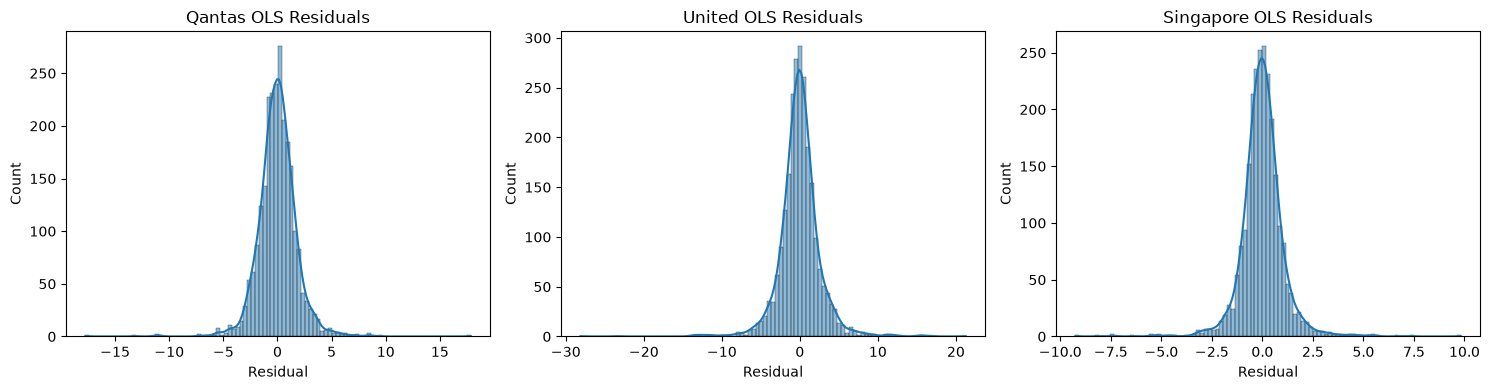

In [13]:
# Residual Dist. Plot
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, (name, model) in zip(axes, models.items()):
    sns.histplot(
        model.resid,
        kde=True,
        ax=ax
    )
    ax.set_title(f"{name} OLS Residuals")
    ax.set_xlabel("Residual")

plt.tight_layout()
plt.show()


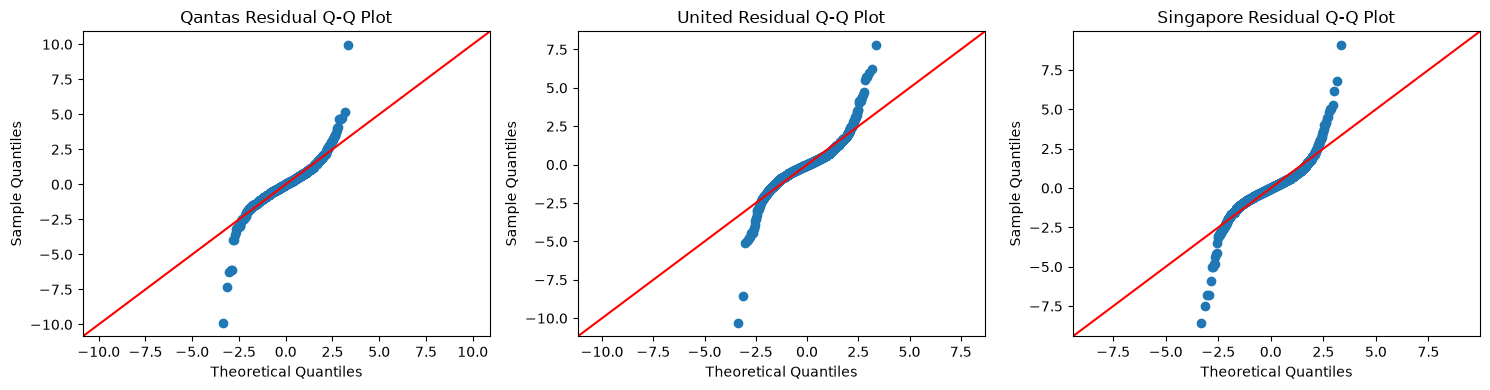

In [14]:
# Q-Q Plot
import matplotlib.pyplot as plt
import statsmodels.api as sm

models = {
    "Qantas": qantas_model,
    "United": united_model,
    "Singapore": singapore_model
}

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, (name, model) in zip(axes, models.items()):

    sm.qqplot(
        model.resid,
        line="45",
        fit=True,
        ax=ax
    )

    ax.set_title(f"{name} Residual Q-Q Plot")
    ax.set_xlabel("Theoretical Quantiles")
    ax.set_ylabel("Sample Quantiles")

plt.tight_layout()
plt.show()


### Step4: HAC Robust Inference

The diagnostic tests reveal significant heteroskedasticity in all three airline regressions and residual serial correlation in the Qantas and United Airlines models.

Therefore, HAC standard errors are employed to obtain more reliable statistical inference.

The HAC covariance estimator is given by:

$$
\widehat{\mathrm{Var}}_{HAC}(\hat{\beta})
=
(X'X)^{-1}\hat{S}(X'X)^{-1}
$$

where $\hat{S}$ accounts for heteroskedasticity and autocovariances of the regression disturbances.

A bandwidth of five lags is used as the baseline specification, with alternative lag lengths considered in subsequent robustness checks.

HAC estimation leaves the OLS coefficient estimates unchanged but adjusts their standard errors, confidence intervals and associated hypothesis tests.

In [15]:
# HAC Estimation
models = {
    "Qantas": qantas_model,
    "United": united_model,
    "Singapore": singapore_model
}

hac_models = {}

qantas_hac = qantas_model.get_robustcov_results(
    cov_type="HAC",
    maxlags=5,
    use_t=True
)

# Qantas Airlines HAC Model Summary
print(qantas_hac.summary())


                            OLS Regression Results                            
Dep. Variable:         Airline_Return   R-squared:                       0.237
Model:                            OLS   Adj. R-squared:                  0.236
Method:                 Least Squares   F-statistic:                     57.20
Date:                Wed, 28 Oct 2026   Prob (F-statistic):           3.36e-46
Time:                        22:34:55   Log-Likelihood:                -4914.2
No. Observations:                2451   AIC:                             9838.
Df Residuals:                    2446   BIC:                             9868.
Df Model:                           4                                         
Covariance Type:                  HAC                                         
                      coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------
Intercept           0.0330      0.061     

In [16]:
united_hac = united_model.get_robustcov_results(
    cov_type="HAC",
    maxlags=5,
    use_t=True
)

# United Airlines HAC Model Summary
print(united_hac.summary())

                            OLS Regression Results                            
Dep. Variable:         Airline_Return   R-squared:                       0.284
Model:                            OLS   Adj. R-squared:                  0.283
Method:                 Least Squares   F-statistic:                     77.02
Date:                Wed, 28 Oct 2026   Prob (F-statistic):           1.46e-61
Time:                        22:34:55   Log-Likelihood:                -5882.0
No. Observations:                2426   AIC:                         1.177e+04
Df Residuals:                    2421   BIC:                         1.180e+04
Df Model:                           4                                         
Covariance Type:                  HAC                                         
                      coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------
Intercept          -0.0305      0.122     

In [17]:
singapore_hac = singapore_model.get_robustcov_results(
    cov_type="HAC",
    maxlags=5,
    use_t=True
)

# Singapore Airlines HAC Model Summary
print(singapore_hac.summary())

                            OLS Regression Results                            
Dep. Variable:         Airline_Return   R-squared:                       0.346
Model:                            OLS   Adj. R-squared:                  0.345
Method:                 Least Squares   F-statistic:                     84.72
Date:                Wed, 28 Oct 2026   Prob (F-statistic):           2.05e-67
Time:                        22:34:55   Log-Likelihood:                -3622.9
No. Observations:                2419   AIC:                             7256.
Df Residuals:                    2414   BIC:                             7285.
Df Model:                           4                                         
Covariance Type:                  HAC                                         
                      coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------
Intercept           0.0410      0.036     

### Re-test Asymmetry with HAC
$$ H_0:\beta_{3i}=0 $$

$$
H_1:\beta_{3i}\neq0
$$

In [18]:
hac_models = {
    "Qantas": qantas_hac,
    "United": united_hac,
    "Singapore": singapore_hac
}

for name, model in hac_models.items():

    print(f"\n===== {name}: HAC Asymmetry Test =====")

    test = model.t_test("Oil_Interaction = 0")

    print(test)



===== Qantas: HAC Asymmetry Test =====
                             Test for Constraints                             
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
c0            -0.0520      0.039     -1.348      0.178      -0.128       0.024

===== United: HAC Asymmetry Test =====
                             Test for Constraints                             
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
c0            -0.0767      0.083     -0.929      0.353      -0.239       0.085

===== Singapore: HAC Asymmetry Test =====
                             Test for Constraints                             
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
c0      

In [19]:
comparison = []

for name in models:

    ols = models[name]
    hac = hac_models[name]

    idx = ols.model.exog_names.index("Oil_Interaction")

    comparison.append({
        "Airline": name,
        "Coefficient": ols.params.iloc[idx],
        "OLS SE": ols.bse.iloc[idx],
        "HAC SE": hac.bse[idx],
        "OLS p-value": ols.pvalues.iloc[idx],
        "HAC p-value": hac.pvalues[idx],
        "HAC Significant (5%)": hac.pvalues[idx] < 0.05
    })

comparison_df = pd.DataFrame(comparison)

display(comparison_df.round(4))


,Airline,Coefficient,OLS SE,HAC SE,OLS p-value,HAC p-value,HAC Significant (5%)
0,Qantas,-0.0520,0.0295,0.0386,0.0780,0.1778,False
1,United,-0.0767,0.0447,0.0825,0.0867,0.3531,False
2,Singapore,-0.0377,0.0178,0.0199,0.0340,0.0586,False


### Interpretation:
The application of HAC standard errors leads to larger standard errors for the interaction coefficients across all three airline regressions.

For Qantas, the p-value increases from 0.0780 to 0.1778, while for United Airlines it rises from 0.0867 to 0.3531. Both remain statistically insignificant at the 5% level.

For Singapore Airlines, the p-value increases from 0.0340 to 0.0586. Consequently, the previously significant asymmetric effect under conventional OLS inference becomes insignificant at the 5% level, although it remains marginally significant at the 10% level.

Overall, none of the three airlines exhibits statistically significant asymmetric oil-price effects at the 5% level after accounting for heteroskedasticity and serial correlation using HAC standard errors.

These findings demonstrate that conventional OLS inference may overstate the statistical evidence of asymmetry and highlight the importance of robust standard errors.

### HAC Directional Effects
$$
H_0:\beta_1=0
$$

$$
H_0:\beta_1+\beta_3=0
$$

In [20]:
direction_results = []

for name, model in hac_models.items():

    tests = {
        "Oil Decrease": "Oil_Return = 0",
        "Oil Increase": "Oil_Return + Oil_Interaction = 0"
    }

    for direction, hypothesis in tests.items():

        test = model.t_test(hypothesis)

        direction_results.append({
            "Airline": name,
            "Direction": direction,
            "Coefficient": float(test.effect.item()),
            "HAC SE": float(test.sd.item()),
            "t-statistic": float(test.tvalue.item()),
            "p-value": float(test.pvalue.item())
        })

hac_direction_df = pd.DataFrame(direction_results)

display(hac_direction_df.round(4))


,Airline,Direction,Coefficient,HAC SE,t-statistic,p-value
0,Qantas,Oil Decrease,-0.0041,0.0255,-0.1624,0.8710
1,Qantas,Oil Increase,-0.0562,0.0351,-1.6012,0.1095
2,United,Oil Decrease,-0.0066,0.0699,-0.0940,0.9251
3,United,Oil Increase,-0.0832,0.0732,-1.1370,0.2557
4,Singapore,Oil Decrease,0.0219,0.0134,1.6341,0.1024
5,Singapore,Oil Increase,-0.0158,0.0203,-0.7775,0.4369


### Interpretation:
The individual directional effects are re-examined using HAC standard errors with five lags.

**Qantas Airways:** The estimated slope during oil-price decreases is -0.0041 (p = 0.8710), while the slope during oil-price increases is -0.0562 (p = 0.1095). Neither effect is statistically significant at the 5% level. Notably, the previously significant negative slope during oil-price increases under conventional OLS inference (p = 0.014) becomes insignificant after HAC adjustment.

**United Airlines:** The estimated slopes are -0.0066 (p = 0.9251) for oil-price decreases and -0.0832 (p = 0.2557) for increases. Both effects are statistically insignificant. As with Qantas, the previously significant negative slope during oil-price increases (OLS p = 0.017) is no longer significant under HAC inference.

**Singapore Airlines:** The estimated slope during oil-price decreases is 0.0219 (p = 0.1024), while the slope during increases is -0.0158 (p = 0.4369). Neither effect is statistically significant at the 5% level.

**Overall**, none of the six directional effects is statistically significant at the 5% level after applying HAC standard errors. Although the estimated slopes differ across directions and airlines, the evidence is insufficient to conclude that any individual directional slope differs significantly from zero.


### HAC Lag Senstivity

In [21]:
sensitivity_results = []

for name, model in models.items():

    for lag in [1, 5, 10]:

        hac = model.get_robustcov_results(
            cov_type="HAC",
            maxlags=lag,
            use_t=True
        )

        test = hac.t_test("Oil_Interaction = 0")

        sensitivity_results.append({
            "Airline": name,
            "HAC Lags": lag,
            "Coefficient": float(test.effect.item()),
            "HAC SE": float(test.sd.item()),
            "p-value": float(test.pvalue.item())
        })

sensitivity_df = pd.DataFrame(sensitivity_results)

display(sensitivity_df.round(4))


,Airline,HAC Lags,Coefficient,HAC SE,p-value
0,Qantas,1,-0.0520,0.0451,0.2484
1,Qantas,5,-0.0520,0.0386,0.1778
2,Qantas,10,-0.0520,0.0304,0.0866
3,United,1,-0.0767,0.1026,0.4551
4,United,5,-0.0767,0.0825,0.3531
5,United,10,-0.0767,0.0621,0.2172
6,Singapore,1,-0.0377,0.0220,0.0868
7,Singapore,5,-0.0377,0.0199,0.0586
8,Singapore,10,-0.0377,0.0205,0.0666


### Interpretation:
To assess the robustness of the asymmetry hypothesis tests, HAC standard errors are calculated using alternative lag lengths of 1, 5, and 10.

Qantas Airways: The p-values decrease from 0.2484 (HAC(1)) to 0.1778 (HAC(5)) and 0.0866 (HAC(10)). Although the asymmetry coefficient remains insignificant at the 5% level across all specifications, it becomes marginally significant at the 10% level under HAC(10). This indicates some sensitivity to bandwidth selection.

United Airlines: The p-values are 0.4551, 0.3531, and 0.2172 for HAC(1), HAC(5), and HAC(10), respectively. The interaction coefficient remains statistically insignificant at both the 5% and 10% levels, indicating consistently weak evidence of asymmetry.

Singapore Airlines: The p-values are 0.0868, 0.0586, and 0.0666 across the three bandwidths. Although the interaction coefficient is not significant at the 5% level, it remains significant at the 10% level under all specifications, suggesting relatively consistent but weak evidence of asymmetric oil-price effects.

Overall, none of the three airlines exhibits statistically significant asymmetry at the 5% level under any of the HAC bandwidth specifications. Singapore Airlines provides the most consistent evidence of marginal asymmetry at the 10% level, while Qantas shows greater sensitivity to bandwidth selection. These results support a cautious interpretation of the asymmetric relationship between oil-price changes and airline stock returns.

### Conclusion
The HAC results indicate weaker statistical evidence of asymmetric oil-price effects compared with conventional OLS inference.

Under HAC(5), none of the three airlines exhibits significant asymmetry at the 5% level. Singapore Airlines shows marginal significance at the 10% level (p = 0.0586), while Qantas (p = 0.1778) and United (p = 0.3531) remain insignificant. Additionally, none of the individual directional slopes is statistically significant at the 5% level.

Sensitivity tests using HAC lags of 1, 5, and 10 confirm that all interaction coefficients remain insignificant at the 5% level, although Singapore consistently shows marginal significance at the 10% level.

Overall, the evidence of asymmetric oil-price effects is limited after robust adjustment, highlighting the importance of accounting for heteroskedasticity and serial correlation.

### Step5: Fit model with Lagged Oil Returns

To address potential non-synchronous trading across international markets, a lagged oil-return specification is estimated as a robustness check.

The model is specified as:

$$
r_{i,t}=\alpha_i+\beta_{1i}OilReturn_{t-1}
+\beta_{2i}D_{t-1}
+\beta_{3i}(OilReturn_{t-1}\times D_{t-1})
+\gamma_i MarketReturn_{i,t}+u_{i,t}
$$

The main hypothesis remains:

$$
H_0:\beta_{3i}=0
$$

Newey-West HAC standard errors with five lags are used for statistical inference. The results are compared with the same-date baseline model to assess sensitivity to the timing of oil-price information.

In [22]:
# Construct Lagged Oil Variables
import pandas as pd
import numpy as np

oil = pd.read_csv(
    "Brent_cleaned.csv",
    parse_dates=["Date"]
)

oil = oil.sort_values("Date").reset_index(drop=True)

# Keep valid oil returns
oil_valid = oil.dropna(
    subset=["Oil_Return"]
).copy()

# Rename lagged explanatory variables
oil_lagged = oil_valid[[
    "Date",
    "Oil_Return",
    "D",
    "Oil_Interaction"
]].rename(columns={
    "Oil_Return": "Oil_Return_Lag",
    "D": "D_Lag",
    "Oil_Interaction": "Oil_Interaction_Lag"
})

# Check
display(oil_lagged.head())

,Date,Oil_Return_Lag,D_Lag,Oil_Interaction_Lag
1,2016-01-05,-2.004521,0.0,0.0
2,2016-01-06,-4.810143,0.0,0.0
3,2016-01-07,-0.948717,0.0,0.0
4,2016-01-08,-5.826295,0.0,0.0
5,2016-01-11,-4.951667,0.0,0.0


In [23]:
qantas = pd.read_csv(r"C:\Users\ALIENWARE\OneDrive\Desktop\26s2\ECMT3150\group project\Qantas_cleaned.csv", parse_dates=["Date"])
united = pd.read_csv(r"United_cleaned.csv", parse_dates=["Date"])
singapore = pd.read_csv(r"Singapore_cleaned.csv", parse_dates=["Date"])

asx = pd.read_csv(r"C:\Users\ALIENWARE\OneDrive\Desktop\26s2\ECMT3150\group project\ASX200_cleaned.csv", parse_dates=["Date"])
sp500 = pd.read_csv(r"C:\Users\ALIENWARE\OneDrive\Desktop\26s2\ECMT3150\group project\SP500_cleaned.csv", parse_dates=["Date"])
sti = pd.read_csv(r"C:\Users\ALIENWARE\OneDrive\Desktop\26s2\ECMT3150\group project\STI_cleaned.csv", parse_dates=["Date"])

In [24]:
# Match Previous Available Brent Returns
def create_lagged_dataset(airline, market, oil_lagged):

    # Merge airline and market index
    df = airline[["Date", "Airline_Return"]].merge(
        market[["Date", "Market_Return"]],
        on="Date",
        how="inner",
        validate="one_to_one"
    )

    df = df.sort_values("Date")

    oil_data = oil_lagged.sort_values("Date")

    # Match latest Brent observation strictly before stock date
    df = pd.merge_asof(
        df,
        oil_data,
        on="Date",
        direction="backward",
        allow_exact_matches=False
    )

    df = df.replace([np.inf, -np.inf], np.nan)

    df = df.dropna(subset=[
        "Airline_Return",
        "Market_Return",
        "Oil_Return_Lag",
        "D_Lag",
        "Oil_Interaction_Lag"
    ])

    return df.reset_index(drop=True)

In [25]:
qantas_lagged = create_lagged_dataset(qantas, asx, oil_lagged)
united_lagged = create_lagged_dataset(united, sp500, oil_lagged)
singapore_lagged = create_lagged_dataset(singapore, sti, oil_lagged)

print("Qantas:", len(qantas_lagged))
print("United:", len(united_lagged))
print("Singapore:", len(singapore_lagged))

Qantas: 2525
United: 2512
Singapore: 2509


### Estimate Lagged OLS Models

In [26]:
import statsmodels.formula.api as smf

lag_formula = (
    "Airline_Return ~ Oil_Return_Lag + D_Lag "
    "+ Oil_Interaction_Lag + Market_Return"
)

qantas_lag_model = smf.ols(
    lag_formula, data=qantas_lagged
).fit()

united_lag_model = smf.ols(
    lag_formula, data=united_lagged
).fit()

singapore_lag_model = smf.ols(
    lag_formula, data=singapore_lagged
).fit()

In [27]:
# Qantas Airlines Lagged Model Summary
print(qantas_lag_model.summary())

                            OLS Regression Results                            
Dep. Variable:         Airline_Return   R-squared:                       0.241
Model:                            OLS   Adj. R-squared:                  0.240
Method:                 Least Squares   F-statistic:                     200.5
Date:                Wed, 28 Oct 2026   Prob (F-statistic):          1.94e-149
Time:                        22:34:57   Log-Likelihood:                -5048.8
No. Observations:                2525   AIC:                         1.011e+04
Df Residuals:                    2520   BIC:                         1.014e+04
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                          coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------
Intercept               0.1864    

In [28]:
# United Airlines Lagged Model Summary
print(united_lag_model.summary())

                            OLS Regression Results                            
Dep. Variable:         Airline_Return   R-squared:                       0.288
Model:                            OLS   Adj. R-squared:                  0.287
Method:                 Least Squares   F-statistic:                     254.0
Date:                Wed, 28 Oct 2026   Prob (F-statistic):          2.26e-183
Time:                        22:34:57   Log-Likelihood:                -6081.2
No. Observations:                2512   AIC:                         1.217e+04
Df Residuals:                    2507   BIC:                         1.220e+04
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                          coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------
Intercept               0.1188    

In [29]:
# Singapore Airlines Lagged Model Summary
print(singapore_lag_model.summary())

                            OLS Regression Results                            
Dep. Variable:         Airline_Return   R-squared:                       0.344
Model:                            OLS   Adj. R-squared:                  0.343
Method:                 Least Squares   F-statistic:                     328.9
Date:                Wed, 28 Oct 2026   Prob (F-statistic):          1.04e-227
Time:                        22:34:57   Log-Likelihood:                -3729.5
No. Observations:                2509   AIC:                             7469.
Df Residuals:                    2504   BIC:                             7498.
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                          coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------
Intercept               0.0227    

### Apply HAC Standard Errors

In [30]:
qantas_lag_hac = qantas_lag_model.get_robustcov_results(
    cov_type="HAC", maxlags=5, use_t=True
)

united_lag_hac = united_lag_model.get_robustcov_results(
    cov_type="HAC", maxlags=5, use_t=True
)

singapore_lag_hac = singapore_lag_model.get_robustcov_results(
    cov_type="HAC", maxlags=5, use_t=True
)

In [31]:
print("Qantas")
print(qantas_lag_hac.t_test("Oil_Interaction_Lag = 0"))

print("United")
print(united_lag_hac.t_test("Oil_Interaction_Lag = 0"))

print("Singapore")
print(singapore_lag_hac.t_test("Oil_Interaction_Lag = 0"))

Qantas
                             Test for Constraints                             
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
c0            -0.0668      0.044     -1.502      0.133      -0.154       0.020
United
                             Test for Constraints                             
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
c0            -0.0841      0.069     -1.225      0.221      -0.219       0.051
Singapore
                             Test for Constraints                             
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
c0             0.0203      0.026      0.784      0.433      -0.030       0.071


In [32]:
# Compare Baseline (Same date) and Lagged HAC Results
def get_asymmetry_result(name, baseline, lagged):

    baseline_test = baseline.t_test("Oil_Interaction = 0")
    lagged_test = lagged.t_test("Oil_Interaction_Lag = 0")

    return {
        "Airline": name,
        "Baseline Coef": float(baseline_test.effect.item()),
        "Baseline HAC p": float(baseline_test.pvalue.item()),
        "Lagged Coef": float(lagged_test.effect.item()),
        "Lagged HAC p": float(lagged_test.pvalue.item())
    }

robustness_df = pd.DataFrame([
    get_asymmetry_result("Qantas", qantas_hac, qantas_lag_hac),
    get_asymmetry_result("United", united_hac, united_lag_hac),
    get_asymmetry_result("Singapore", singapore_hac, singapore_lag_hac)
])

display(robustness_df.round(4))

,Airline,Baseline Coef,Baseline HAC p,Lagged Coef,Lagged HAC p
0,Qantas,-0.0520,0.1778,-0.0668,0.1333
1,United,-0.0767,0.3531,-0.0841,0.2209
2,Singapore,-0.0377,0.0586,0.0203,0.4330


### Common Sample Robustness Check
To ensure comparability between the same-date and lagged oil-return specifications, both models are re-estimated using identical observations.

The common sample is constructed by retaining only trading dates available in both datasets for each airline.

This allows differences in the estimated coefficients to be attributed more directly to the timing specification rather than changes in sample composition.

HAC standard errors with five lags are used consistently in both models.

In [51]:
datasets["Qantas"]["Date"] = pd.to_datetime(datasets["Qantas"]["Date"])
datasets["United"]["Date"] = pd.to_datetime(datasets["United"]["Date"])
datasets["Singapore"]["Date"] = pd.to_datetime(datasets["Singapore"]["Date"])

qantas_lagged["Date"] = pd.to_datetime(qantas_lagged["Date"])
united_lagged["Date"] = pd.to_datetime(united_lagged["Date"])
singapore_lagged["Date"] = pd.to_datetime(singapore_lagged["Date"])

In [52]:
def common_sample(baseline, lagged):

    dates = set(baseline["Date"]) & set(lagged["Date"])

    base_common = baseline[
        baseline["Date"].isin(dates)
    ].copy()

    lag_common = lagged[
        lagged["Date"].isin(dates)
    ].copy()

    base_common = base_common.sort_values("Date")
    lag_common = lag_common.sort_values("Date")

    assert base_common["Date"].reset_index(drop=True).equals(
        lag_common["Date"].reset_index(drop=True)
    )

    return base_common, lag_common

In [53]:
q_base, q_lag = common_sample(
    datasets["Qantas"], qantas_lagged
)

u_base, u_lag = common_sample(
    datasets["United"], united_lagged
)

s_base, s_lag = common_sample(
    datasets["Singapore"], singapore_lagged
)

print("Qantas:", len(q_base), len(q_lag))
print("United:", len(u_base), len(u_lag))
print("Singapore:", len(s_base), len(s_lag))

Qantas: 2450 2450
United: 2425 2425
Singapore: 2418 2418


In [54]:
# Re-estimate
base_formula = (
    "Airline_Return ~ Oil_Return + D "
    "+ Oil_Interaction + Market_Return"
)

lag_formula = (
    "Airline_Return ~ Oil_Return_Lag + D_Lag "
    "+ Oil_Interaction_Lag + Market_Return"
)

def compare_common_sample(name, base, lag):

    base_model = smf.ols(
        base_formula, data=base
    ).fit(
        cov_type="HAC",
        cov_kwds={"maxlags": 5},
        use_t=True
    )

    lag_model = smf.ols(
        lag_formula, data=lag
    ).fit(
        cov_type="HAC",
        cov_kwds={"maxlags": 5},
        use_t=True
    )

    return {
        "Airline": name,
        "Common N": len(base),
        "Baseline Coef": base_model.params["Oil_Interaction"],
        "Baseline p": base_model.pvalues["Oil_Interaction"],
        "Lagged Coef": lag_model.params["Oil_Interaction_Lag"],
        "Lagged p": lag_model.pvalues["Oil_Interaction_Lag"]
    }

In [55]:
common_results = pd.DataFrame([
    compare_common_sample("Qantas", q_base, q_lag),
    compare_common_sample("United", u_base, u_lag),
    compare_common_sample("Singapore", s_base, s_lag)
])

display(common_results.round(4))

,Airline,Common N,Baseline Coef,Baseline p,Lagged Coef,Lagged p
0,Qantas,2450,-0.0520,0.1780,-0.0733,0.1071
1,United,2425,-0.0766,0.3532,-0.0805,0.2791
2,Singapore,2418,-0.0377,0.0586,0.0230,0.3876


### Conclusion
1. Using lagged oil returns, none of the three airlines shows significant asymmetry under HAC inference. Qantas (p = 0.1333) and United Airlines (p = 0.2209) retain negative interaction coefficients, but both remain insignificant. Singapore Airlines becomes clearly insignificant (p = 0.4330), and its interaction coefficient changes sign from negative to positive.

Overall, the lagged specification does not support robust asymmetric oil-price effects. This suggests that the baseline findings are sensitive to the timing of oil-price information.

The empirical results provide limited evidence of asymmetric oil-price effects on airline stock returns. Although the baseline estimates suggest more negative oil-return slopes during oil-price increases, these differences are not statistically significant at the 5% level under HAC inference. The lagged oil-return specification further weakens the evidence, particularly for Singapore Airlines, whose interaction coefficient changes sign. Meanwhile, market-wide returns are strongly associated with airline stock returns. Overall, the findings suggest that the estimated asymmetry is sensitive to model specification and timing assumptions, rather than representing a robust empirical relationship.

2.  The common-sample results confirm that none of the asymmetric oil-price interaction coefficients is statistically significant at the 5% level under Newey–West HAC inference.
For Qantas and United Airlines, the interaction coefficients remain negative across both specifications, although they are statistically insignificant. In contrast, Singapore Airlines’ interaction coefficient changes from -0.0377 in the baseline model to +0.0230 in the lagged model, with the corresponding p-value increasing from 0.0586 to 0.3876.
These results suggest that the estimated asymmetry for Singapore Airlines is sensitive to the timing specification, rather than merely reflecting differences in sample composition. Overall, the common-sample analysis reinforces the conclusion that evidence of asymmetric oil-price effects is not robust.

### Step6: Cross Airline Comparison

The estimated coefficients from the baseline models are compared across Qantas Airways, United Airlines, and Singapore Airlines.

The oil-price decrease and increase slopes are defined as:

$$
\beta_{\text{down},i}=\beta_{1i}
$$

$$
\beta_{\text{up},i}=\beta_{1i}+\beta_{3i}
$$

The difference between the two slopes is:

$$
\Delta_i=\beta_{3i}
$$

Newey-West HAC standard errors with five lags are used to assess statistical significance.

In [33]:
comparison_df = pd.DataFrame({
    "Airline": ["Qantas", "United", "Singapore"],
    "Oil Decrease Slope": [
        qantas_model.params["Oil_Return"],
        united_model.params["Oil_Return"],
        singapore_model.params["Oil_Return"]
    ],
    "Oil Increase Slope": [
        qantas_model.params["Oil_Return"] + qantas_model.params["Oil_Interaction"],
        united_model.params["Oil_Return"] + united_model.params["Oil_Interaction"],
        singapore_model.params["Oil_Return"] + singapore_model.params["Oil_Interaction"]
    ],
    "Asymmetry Coefficient": [
        qantas_model.params["Oil_Interaction"],
        united_model.params["Oil_Interaction"],
        singapore_model.params["Oil_Interaction"]
    ],
    "HAC p-value": [
        qantas_hac.t_test("Oil_Interaction = 0").pvalue.item(),
        united_hac.t_test("Oil_Interaction = 0").pvalue.item(),
        singapore_hac.t_test("Oil_Interaction = 0").pvalue.item()
    ]
})

display(comparison_df.round(4))

,Airline,Oil Decrease Slope,Oil Increase Slope,Asymmetry Coefficient,HAC p-value
0,Qantas,-0.0041,-0.0562,-0.0520,0.1778
1,United,-0.0066,-0.0832,-0.0767,0.3531
2,Singapore,0.0219,-0.0158,-0.0377,0.0586


### Visualise Directional Effects

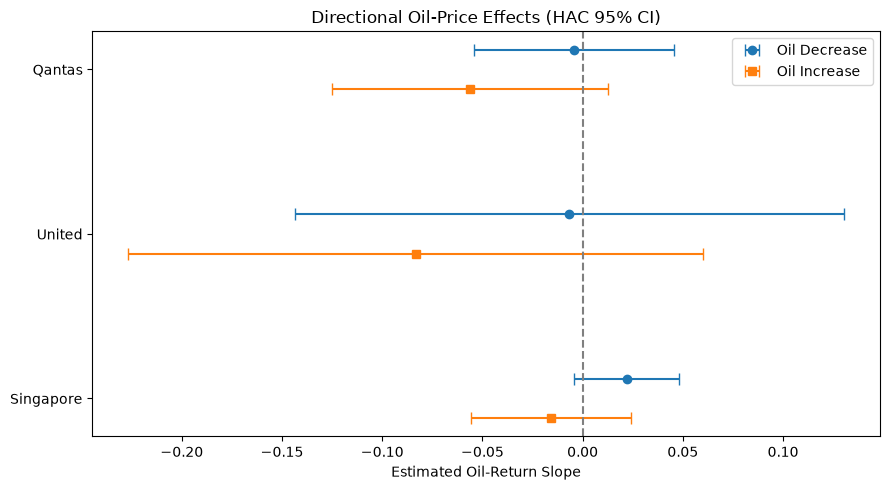

In [34]:
def get_effect(model, hypothesis):
    test = model.t_test(hypothesis)
    return (
        float(test.effect.item()),
        float(test.sd.item())
    )

# Qantas
q_down, q_down_se = get_effect(qantas_hac, "Oil_Return = 0")
q_up, q_up_se = get_effect(
    qantas_hac, "Oil_Return + Oil_Interaction = 0"
)

# United
u_down, u_down_se = get_effect(united_hac, "Oil_Return = 0")
u_up, u_up_se = get_effect(
    united_hac, "Oil_Return + Oil_Interaction = 0"
)

# Singapore
s_down, s_down_se = get_effect(singapore_hac, "Oil_Return = 0")
s_up, s_up_se = get_effect(
    singapore_hac, "Oil_Return + Oil_Interaction = 0"
)

names = ["Qantas", "United", "Singapore"]

down = np.array([q_down, u_down, s_down])
up = np.array([q_up, u_up, s_up])

down_se = np.array([q_down_se, u_down_se, s_down_se])
up_se = np.array([q_up_se, u_up_se, s_up_se])

y = np.arange(3)

fig, ax = plt.subplots(figsize=(9, 5))

ax.errorbar(
    down, y - 0.12,
    xerr=1.96 * down_se,
    fmt="o",
    capsize=4,
    label="Oil Decrease"
)

ax.errorbar(
    up, y + 0.12,
    xerr=1.96 * up_se,
    fmt="s",
    capsize=4,
    label="Oil Increase"
)

ax.axvline(0, color="gray", linestyle="--")

ax.set_yticks(y)
ax.set_yticklabels(names)
ax.invert_yaxis()

ax.set_xlabel("Estimated Oil-Return Slope")
ax.set_title("Directional Oil-Price Effects (HAC 95% CI)")
ax.legend()

plt.tight_layout()
plt.show()

To investigate potential differences in asymmetric oil-price effects across airlines, the estimated interaction coefficients are compared.

A formal pairwise comparison would test:

$$
H_0:\beta_{3,i}-\beta_{3,j}=0
$$

The estimated interaction coefficients are:

$$
\hat{\beta}_{3,Qantas}=-0.0520
$$

$$
\hat{\beta}_{3,United}=-0.0767
$$

$$
\hat{\beta}_{3,Singapore}=-0.0377
$$

Although United Airlines has the largest negative estimated interaction coefficient, differences in coefficient magnitudes alone do not establish statistically significant differences across airlines.

Since separate HAC regressions do not directly provide the covariance between coefficient estimates from different airlines, formal cross-airline significance tests are not conducted at this stage. The comparisons are therefore descriptive.

In [35]:
pairwise_df = pd.DataFrame({
    "Comparison": [
        "Qantas - United",
        "Qantas - Singapore",
        "United - Singapore"
    ],
    "Difference": [
        qantas_model.params["Oil_Interaction"]
        - united_model.params["Oil_Interaction"],

        qantas_model.params["Oil_Interaction"]
        - singapore_model.params["Oil_Interaction"],

        united_model.params["Oil_Interaction"]
        - singapore_model.params["Oil_Interaction"]
    ]
})

display(pairwise_df.round(4))

,Comparison,Difference
0,Qantas - United,0.0246
1,Qantas - Singapore,-0.0144
2,United - Singapore,-0.0390


### Conclusion:
The baseline results show negative interaction coefficients for all three airlines, suggesting lower estimated oil-return slopes during oil-price increases than decreases.

United Airlines exhibits the largest negative interaction coefficient (-0.0767), followed by Qantas (-0.0520) and Singapore Airlines (-0.0377). However, none of these coefficients is statistically significant at the 5% level under HAC(5) inference.

The directional effect plot further shows that all six HAC 95% confidence intervals include zero, indicating that none of the individual directional slopes is statistically significant at the 5% level.

The lagged oil-return robustness check produces negative interaction coefficients for Qantas and United, while Singapore's coefficient changes sign and becomes clearly insignificant.

Overall, the results provide limited evidence of robust asymmetric oil-price effects across the three airlines. Although the estimated coefficients differ in magnitude, these differences should not be interpreted as statistically significant cross-airline differences without formal joint testing.

### Step7: Prediction

### Framework 
To evaluate the predictive contribution of oil-price information, two competing regression models are compared.

**Model A: Market-Only Benchmark**

$$
r_{i,t}=\alpha_i+\gamma_i MarketReturn_{i,t}+u_{i,t}
$$

**Model B: Full Asymmetric Model**

$$
r_{i,t}=\alpha_i+\beta_{1i}OilReturn_t+\beta_{2i}D_t
+\beta_{3i}(OilReturn_t\times D_t)
+\gamma_i MarketReturn_{i,t}+u_{i,t}
$$

The dataset is divided chronologically into an 80% training sample and a 20% testing sample.

Predictive performance is evaluated using Root Mean Squared Error (RMSE) and Mean Absolute Error (MAE).

Lower prediction errors indicate better out-of-sample performance.

Since contemporaneous market and oil returns are used, this exercise evaluates conditional out-of-sample predictions rather than strictly feasible real-time forecasts.

In [36]:
# Split Time Series into Train and Test Sets
def split_time_series(df, train_ratio=0.8):

    df = df.copy()

    df["Date"] = pd.to_datetime(df["Date"])

    df = df.sort_values("Date").reset_index(drop=True)

    split_idx = int(len(df) * train_ratio)

    train = df.iloc[:split_idx].copy()
    test = df.iloc[split_idx:].copy()

    return train, test

In [37]:
qantas_train, qantas_test = split_time_series(
    datasets["Qantas"]
)

united_train, united_test = split_time_series(
    datasets["United"]
)

singapore_train, singapore_test = split_time_series(
    datasets["Singapore"]
)

In [38]:
print("Qantas:", len(qantas_train), len(qantas_test))
print("United:", len(united_train), len(united_test))
print("Singapore:", len(singapore_train), len(singapore_test))

Qantas: 1960 491
United: 1940 486
Singapore: 1935 484


In [39]:
# Estimate Models
market_formula = "Airline_Return ~ Market_Return"

full_formula = (
    "Airline_Return ~ Oil_Return + D "
    "+ Oil_Interaction + Market_Return"
)

def fit_prediction_models(train):

    market_model = smf.ols(
        market_formula,
        data=train
    ).fit()

    full_model = smf.ols(
        full_formula,
        data=train
    ).fit()

    return market_model, full_model

In [40]:
q_market, q_full = fit_prediction_models(qantas_train)

u_market, u_full = fit_prediction_models(united_train)

s_market, s_full = fit_prediction_models(singapore_train)

In [41]:
# Out-of-Sample Prediction
# Qantas
qantas_test["Pred_Market"] = q_market.predict(qantas_test)
qantas_test["Pred_Full"] = q_full.predict(qantas_test)

# United
united_test["Pred_Market"] = u_market.predict(united_test)
united_test["Pred_Full"] = u_full.predict(united_test)

# Singapore
singapore_test["Pred_Market"] = s_market.predict(singapore_test)
singapore_test["Pred_Full"] = s_full.predict(singapore_test)

In [42]:
display(qantas_test[
    ["Date", "Airline_Return", "Pred_Market", "Pred_Full"]
].head())

,Date,Airline_Return,Pred_Market,Pred_Full
1960,2023-12-22,0.000000,-0.039475,-0.038407
1961,2023-12-28,1.430055,0.751133,0.764526
1962,2023-12-29,-1.224505,-0.336884,-0.330847
1963,2024-01-03,-0.619197,-1.492580,-1.469291
1964,2024-01-04,-0.831606,-0.421482,-0.415215


The estimated models are applied to the testing samples to generate out-of-sample predictions of daily airline stock returns.

For each airline, two sets of predictions are obtained: one from the market-only benchmark and another from the full asymmetric model incorporating Brent oil-price variables.

The predicted values are compared with actual airline returns to assess whether including oil-price information improves predictive performance.

The overall prediction accuracy will be evaluated using RMSE and MAE in the following step.

### Evaluate prediction performance
Out-of-sample prediction accuracy is evaluated using two measures.

**Root Mean Squared Error (RMSE):**

$$
RMSE=\sqrt{\frac{1}{N}\sum_{t=1}^{N}(r_t-\hat r_t)^2}
$$

**Mean Absolute Error (MAE):**

$$
MAE=\frac{1}{N}\sum_{t=1}^{N}|r_t-\hat r_t|
$$

A lower RMSE or MAE indicates better predictive performance.

The full asymmetric model is compared with the market-only benchmark to assess whether oil-price variables provide additional predictive information beyond general market movements.

In [43]:
def evaluate_prediction(name, test):

    actual = test["Airline_Return"]

    market_pred = test["Pred_Market"]
    full_pred = test["Pred_Full"]

    market_rmse = np.sqrt(np.mean((actual - market_pred) ** 2))
    full_rmse = np.sqrt(np.mean((actual - full_pred) ** 2))

    market_mae = np.mean(np.abs(actual - market_pred))
    full_mae = np.mean(np.abs(actual - full_pred))

    return {
        "Airline": name,
        "Market RMSE": market_rmse,
        "Full RMSE": full_rmse,
        "Market MAE": market_mae,
        "Full MAE": full_mae,
        "RMSE Improvement (%)":
            100 * (market_rmse - full_rmse) / market_rmse
    }

In [44]:
prediction_results = pd.DataFrame([
    evaluate_prediction("Qantas", qantas_test),
    evaluate_prediction("United", united_test),
    evaluate_prediction("Singapore", singapore_test)
])

display(prediction_results.round(4))

,Airline,Market RMSE,Full RMSE,Market MAE,Full MAE,RMSE Improvement (%)
0,Qantas,1.5471,1.5476,1.1261,1.1291,-0.0285
1,United,2.6388,2.6405,1.8849,1.8859,-0.0666
2,Singapore,0.8947,0.8963,0.5575,0.5579,-0.1787


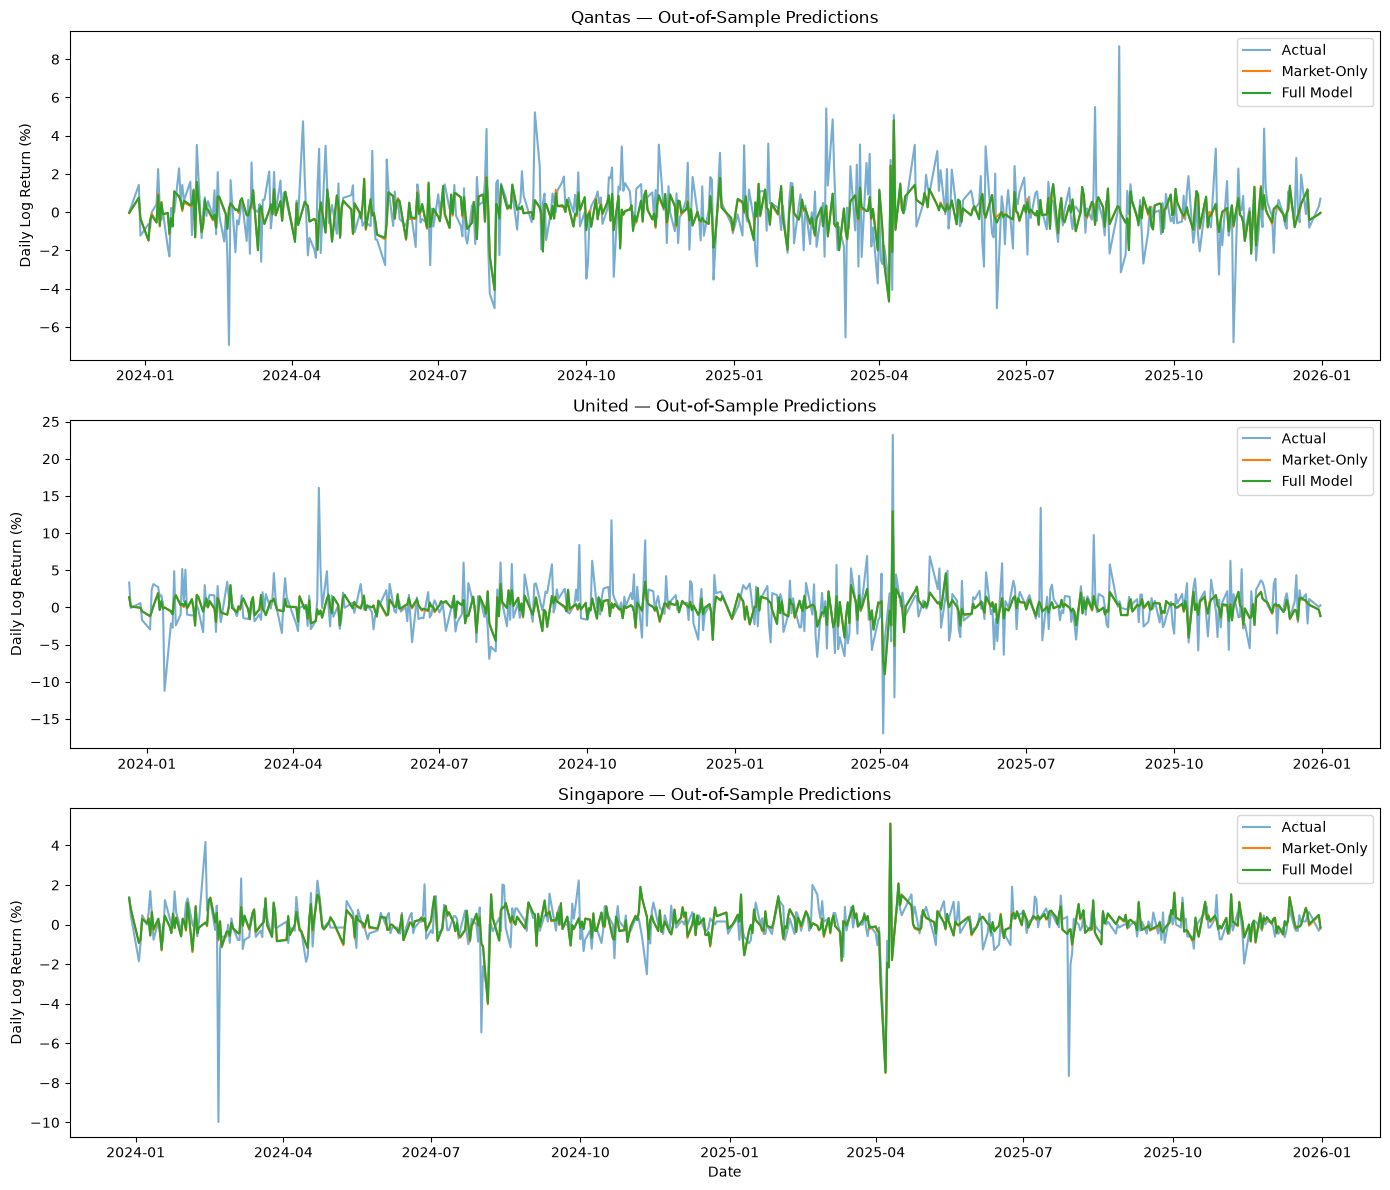

In [45]:
fig, axes = plt.subplots(3, 1, figsize=(14, 12))

# Qantas
axes[0].plot(qantas_test["Date"], qantas_test["Airline_Return"],
             label="Actual", alpha=0.6)
axes[0].plot(qantas_test["Date"], qantas_test["Pred_Market"],
             label="Market-Only")
axes[0].plot(qantas_test["Date"], qantas_test["Pred_Full"],
             label="Full Model")
axes[0].set_title("Qantas — Out-of-Sample Predictions")
axes[0].set_ylabel("Daily Log Return (%)")
axes[0].legend()

# United
axes[1].plot(united_test["Date"], united_test["Airline_Return"],
             label="Actual", alpha=0.6)
axes[1].plot(united_test["Date"], united_test["Pred_Market"],
             label="Market-Only")
axes[1].plot(united_test["Date"], united_test["Pred_Full"],
             label="Full Model")
axes[1].set_title("United — Out-of-Sample Predictions")
axes[1].set_ylabel("Daily Log Return (%)")
axes[1].legend()

# Singapore
axes[2].plot(singapore_test["Date"], singapore_test["Airline_Return"],
             label="Actual", alpha=0.6)
axes[2].plot(singapore_test["Date"], singapore_test["Pred_Market"],
             label="Market-Only")
axes[2].plot(singapore_test["Date"], singapore_test["Pred_Full"],
             label="Full Model")
axes[2].set_title("Singapore — Out-of-Sample Predictions")
axes[2].set_xlabel("Date")
axes[2].set_ylabel("Daily Log Return (%)")
axes[2].legend()

plt.tight_layout()

plt.savefig(
    "Out_of_Sample_Predictions.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


### Interpretation of Out-of-Sample Predictive Performance

The out-of-sample results indicate that incorporating Brent oil-price variables does not improve predictive performance relative to the market-only benchmark.

For Qantas, United Airlines, and Singapore Airlines, the RMSE improvements are -0.0285%, -0.0666%, and -0.1787%, respectively. The full asymmetric model also produces slightly higher MAE values across all three airlines.

The prediction plots show that the market-only and full-model predictions largely overlap, while both models fail to capture some extreme movements in actual airline stock returns.

Overall, Brent oil-price variables provide little incremental predictive value beyond market returns in the testing period. However, these results reflect conditional out-of-sample predictions using contemporaneous explanatory variables rather than genuine real-time forecasts.


### Step8: Final results

### Final Regression Table

In [46]:
models = {
    "Qantas": qantas_model,
    "United": united_model,
    "Singapore": singapore_model
}

hac_models = {
    "Qantas": qantas_hac,
    "United": united_hac,
    "Singapore": singapore_hac
}

variables = [
    "Intercept",
    "Oil_Return",
    "D",
    "Oil_Interaction",
    "Market_Return"
]

def format_coefficient(ols, hac, variable):
    idx = ols.model.exog_names.index(variable)

    coefficient = ols.params.iloc[idx]
    se = hac.bse[idx]
    p = hac.pvalues[idx]

    stars = "***" if p < 0.01 else "**" if p < 0.05 else "*" if p < 0.10 else ""

    return f"{coefficient:.4f}{stars} ({se:.4f})"

regression_table = pd.DataFrame({
    "Variable": variables,
    "Qantas": [
        format_coefficient(qantas_model, qantas_hac, v)
        for v in variables
    ],
    "United": [
        format_coefficient(united_model, united_hac, v)
        for v in variables
    ],
    "Singapore": [
        format_coefficient(singapore_model, singapore_hac, v)
        for v in variables
    ]
})

display(regression_table)

,Variable,Qantas,United,Singapore
0,Intercept,0.0330 (0.0607),-0.0305 (0.1222),0.0410 (0.0356)
1,Oil_Return,-0.0041 (0.0255),-0.0066 (0.0699),0.0219 (0.0134)
2,D,0.0611 (0.1038),0.1058 (0.1944),-0.0376 (0.0571)
3,Oil_Interaction,-0.0520 (0.0386),-0.0767 (0.0825),-0.0377* (0.0199)
4,Market_Return,1.0615*** (0.0776),1.5154*** (0.0929),0.9247*** (0.0530)


Note: Standard errors reported in parentheses are HAC robust standard errors with five lags. Statistical significance is indicated by ***, **, and * at the 1%, 5%, and 10% levels, respectively, based on HAC-adjusted p-values.

### Asymmetry & Robustness Table

In [47]:
def get_test_pvalue(model, hypothesis):
    return float(model.t_test(hypothesis).pvalue.item())

asymmetry_table = pd.DataFrame({
    "Airline": ["Qantas", "United", "Singapore"],

    "Asymmetry Coef": [
        qantas_model.params["Oil_Interaction"],
        united_model.params["Oil_Interaction"],
        singapore_model.params["Oil_Interaction"]
    ],

    "OLS p-value": [
        get_test_pvalue(qantas_model, "Oil_Interaction = 0"),
        get_test_pvalue(united_model, "Oil_Interaction = 0"),
        get_test_pvalue(singapore_model, "Oil_Interaction = 0")
    ],

    "HAC(5) p-value": [
        get_test_pvalue(qantas_hac, "Oil_Interaction = 0"),
        get_test_pvalue(united_hac, "Oil_Interaction = 0"),
        get_test_pvalue(singapore_hac, "Oil_Interaction = 0")
    ],

    "Lagged HAC p-value": [
        get_test_pvalue(qantas_lag_hac, "Oil_Interaction_Lag = 0"),
        get_test_pvalue(united_lag_hac, "Oil_Interaction_Lag = 0"),
        get_test_pvalue(singapore_lag_hac, "Oil_Interaction_Lag = 0")
    ]
})

display(asymmetry_table.round(4))

,Airline,Asymmetry Coef,OLS p-value,HAC(5) p-value,Lagged HAC p-value
0,Qantas,-0.0520,0.0780,0.1778,0.1333
1,United,-0.0767,0.0867,0.3531,0.2209
2,Singapore,-0.0377,0.0340,0.0586,0.4330


### Interpretation of Asymmetry and Robustness Tests

The results indicate that the statistical evidence of asymmetric oil-price effects weakens after robust adjustment. Under conventional OLS inference, Singapore Airlines exhibits significant asymmetry at the 5% level (p = 0.0340), while Qantas and United are marginally significant at the 10% level.

However, after applying HAC standard errors, none of the interaction coefficients remains significant at the 5% level. The lagged oil-return specification further weakens the evidence, particularly for Singapore Airlines, whose interaction coefficient changes sign and becomes statistically insignificant (p = 0.4330).

Overall, the findings provide insufficient evidence of robust asymmetric relationships between oil-price changes and airline stock returns. The results are sensitive to the inference method and timing specification.

The apparent asymmetric effects observed under conventional OLS inference are not robust to HAC adjustment and alternative oil-return timing specifications.

### Model Diagnostics Table

In [48]:
lb10 = lb_df[lb_df["Lag"] == 10][
    ["Airline", "p-value"]
].rename(columns={
    "p-value": "Ljung-Box p (10)"
})

diagnostic_table = (
    bp_df[["Airline", "LM p-value"]]
    .merge(lb10, on="Airline")
    .merge(
        jb_df[["Airline", "p-value"]].rename(
            columns={"p-value": "JB p-value"}
        ),
        on="Airline"
    )
)

display(diagnostic_table.round(5))

,Airline,LM p-value,Ljung-Box p (10),JB p-value
0,Qantas,0.00000,0.00000,0.0
1,United,0.00000,0.00003,0.0
2,Singapore,0.00006,0.16086,0.0


### Interpretation of Model Diagnostic Tests

The diagnostic tests reveal significant heteroskedasticity in all three airline regressions, as indicated by the Breusch–Pagan test (p < 0.001).

The Ljung–Box test at lag 10 detects significant residual serial correlation for Qantas and United Airlines (p < 0.001), while Singapore Airlines shows no significant evidence of serial correlation (p = 0.16086).

Additionally, the Jarque–Bera test rejects residual normality for all three airlines (p < 0.001), suggesting non-normal residual distributions.

Overall, these findings indicate that conventional OLS inference may be unreliable due to heteroskedasticity and serial correlation. Therefore, Newey–West HAC standard errors are employed to obtain more reliable statistical inference.

### Final Conclusion, Limitations & Further Improvements

### Final Conclusion

The empirical analysis provides limited evidence of asymmetric relationships between Brent oil-price changes and airline stock returns.

Although OLS results suggest negative asymmetric effects, these findings weaken after applying HAC standard errors. None of the three airlines exhibits statistically significant asymmetry at the 5% level under HAC inference, although Singapore Airlines shows marginal significance at the 10% level.

The lagged oil-return robustness check further weakens the evidence, particularly for Singapore Airlines, whose interaction coefficient changes sign. Moreover, incorporating oil-price variables does not improve out-of-sample predictive performance relative to the market-only benchmark.

Overall, the results suggest that asymmetric oil-price effects are not robust across inference methods and timing specifications. Market-wide movements appear to play a more important role in explaining daily airline stock returns.

### Limitations

1. non-synchronous trading: Brent oil prices and airline stocks are observed across different markets and time zones. Same-date matching may introduce temporal misalignment, while the lagged specification does not fully resolve differences in information availability.

2. omitted variables: The model controls for market returns but excludes potentially relevant factors such as exchange rates, fuel-hedging strategies, travel demand and airline-specific announcements. This may affect coefficient estimates and limits causal interpretation.

3. model specification: The linear regression assumes constant directional slopes throughout the sample, potentially overlooking time-varying relationships, nonlinear dynamics and structural breaks, particularly during the COVID-19 pandemic.

4. cross-airline comparability: Separate regressions allow descriptive comparisons, but differences in estimated coefficients have not been formally tested using a joint econometric framework.

### Further Improvements

1. more precise timestamp-based alignment of oil prices and stock returns could reduce non-synchronous trading issues. Re-estimating baseline and lagged models on a common sample would also strengthen robustness comparisons.

2. incorporating additional controls, such as exchange rates, airline fuel-hedging exposure and travel-demand indicators, could help reduce omitted-variable concerns

3. rolling-window regressions, regime-switching models or ARMAX–GARCH extensions could be explored to capture time-varying relationships and volatility dynamics.

4. a pooled airline model with interaction terms and appropriate covariance estimation could formally test whether asymmetric oil-price sensitivities differ significantly across airlines.